<a href="https://colab.research.google.com/github/janamaher30/Machine-Learning-Project-/blob/main/Part_A_Models_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [124]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [125]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [126]:
processed_path = "/content/drive/MyDrive/Processed"

import os
print(os.listdir(processed_path))

['outlier_analysis.csv', 'validation.csv', 'scaler.pkl', 'test.csv', 'train.csv']


In [127]:
train_df = pd.read_csv(os.path.join(processed_path, "train.csv"))
val_df = pd.read_csv(os.path.join(processed_path, "validation.csv"))
test_df = pd.read_csv(os.path.join(processed_path, "test.csv"))

print("Training Data:", train_df.shape)
print("Validation Data:", val_df.shape)
print("Testing Data:", test_df.shape)

Training Data: (6911, 6)
Validation Data: (1481, 6)
Testing Data: (1481, 6)


In [128]:
print("Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

print("\nMissing values:")
print(train_df.isnull().sum())

Columns:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']

First 5 rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,0.780588,0.844649,-0.986918,-1.491723,-0.560875,75.0
1,0.394152,0.729308,-0.986918,-0.318879,-1.606897,72.0
2,1.167024,0.786978,1.013255,1.440386,0.485147,81.0
3,0.394152,-0.539434,-0.986918,-0.318879,0.485147,48.0
4,-0.765155,1.421349,1.013255,0.267543,-1.606897,76.0



Missing values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


In [129]:
X_train = train_df.drop(columns=["Performance Index"])
y_train = train_df["Performance Index"]

X_val = val_df.drop(columns=["Performance Index"])
y_val = val_df["Performance Index"]

X_test = test_df.drop(columns=["Performance Index"])
y_test = test_df["Performance Index"]

In [130]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (6911, 5)
y_train: (6911,)


In [131]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

LinearRegression()

In [132]:
print("Intercept:", lr_model.intercept_)

print("\nCoefficients:")
for feature, coef in zip(X_train.columns, lr_model.coef_):
    print(feature, ":", coef)

Intercept: 55.08247721024455

Coefficients:
Hours Studied : 7.37313050522788
Previous Scores : 17.656238706050484
Extracurricular Activities : 0.27839862508898283
Sleep Hours : 0.8014732246681491
Sample Question Papers Practiced : 0.5546506174086581


In [133]:
y_pred = lr_model.predict(X_train)

print("First 5 Predictions:")
print(y_pred[:5])

print("\nFirst 5 Actual Values:")
print(y_train.iloc[:5].values)

First 5 Predictions:
[73.96974818 69.4438593  79.28778195 48.20300292 74.1418239 ]

First 5 Actual Values:
[75. 72. 81. 48. 76.]


In [134]:
errors = y_train.values - y_pred

print("First 5 Errors:")
print(errors[:5])

First 5 Errors:
[ 1.03025182  2.5561407   1.71221805 -0.20300292  1.8581761 ]


In [135]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [136]:
y_val_pred = lr_model.predict(X_val)

In [137]:
mae = mean_absolute_error(y_val, y_val_pred)

mse = mean_squared_error(y_val, y_val_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_val, y_val_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.5968564874126214
MSE: 3.9906274780224864
RMSE: 1.9976554953300847
R2 Score: 0.9889412776643998


In [138]:
train_mae = mean_absolute_error(y_train, y_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred))
train_r2 = r2_score(y_train, y_pred)

print("Training MAE:", train_mae)
print("Training RMSE:", train_rmse)
print("Training R2:", train_r2)

Training MAE: 1.613460968220742
Training RMSE: 2.0282425481726403
Training R2: 0.9888937265788157


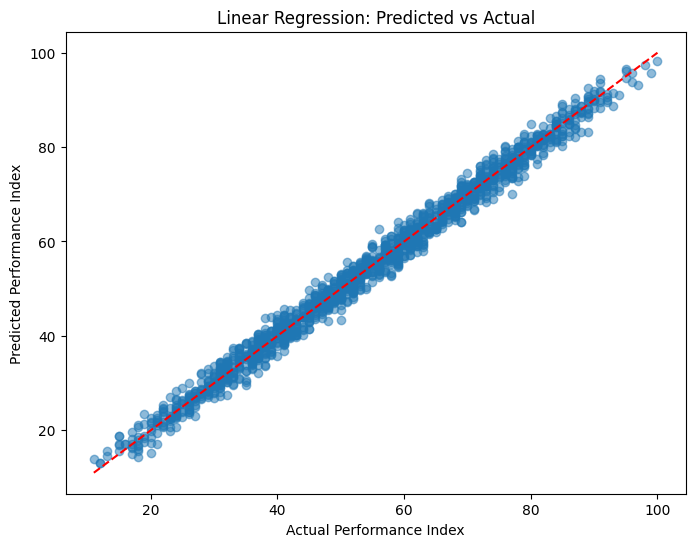

In [139]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_val_pred, alpha=0.5)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    'r--'
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Linear Regression: Predicted vs Actual")

plt.show()

In [140]:
from sklearn.neighbors import KNeighborsRegressor

In [141]:
knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train, y_train)

KNeighborsRegressor()

In [142]:
knn_val_pred = knn_model.predict(X_val)

print("First 5 KNN Predictions:")
print(knn_val_pred[:5])

print("\nFirst 5 Actual Values:")
print(y_val.iloc[:5].values)

First 5 KNN Predictions:
[62.  71.4 77.6 50.8 57.6]

First 5 Actual Values:
[62. 71. 80. 48. 60.]


In [143]:
knn_mae = mean_absolute_error(y_val, knn_val_pred)

knn_mse = mean_squared_error(y_val, knn_val_pred)

knn_rmse = np.sqrt(knn_mse)

knn_r2 = r2_score(y_val, knn_val_pred)

print("KNN MAE:", knn_mae)
print("KNN MSE:", knn_mse)
print("KNN RMSE:", knn_rmse)
print("KNN R2:", knn_r2)

KNN MAE: 2.372180958811614
KNN MSE: 8.909061444969614
KNN RMSE: 2.9848050932966483
KNN R2: 0.9753114422898871


In [144]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]

knn_results = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)

    knn_results.append((k, mae, rmse))

In [145]:
results_df = pd.DataFrame(
    knn_results,
    columns=["K", "MAE", "RMSE"]
)

display(results_df)

,K,MAE,RMSE
0,1,3.339635,4.171379
1,3,2.502363,3.128671
2,5,2.372181,2.984805
3,7,2.373589,2.959470
4,9,2.374522,2.958087
5,11,2.340249,2.921736
6,13,2.300680,2.882951
7,15,2.255143,2.841382
8,17,2.245740,2.828252
9,19,2.235332,2.829029


In [146]:
best_result = results_df.loc[results_df["RMSE"].idxmin()]

print("Best K:", best_result["K"])
print("Best RMSE:", best_result["RMSE"])
print("Best MAE:", best_result["MAE"])

Best K: 17.0
Best RMSE: 2.8282524114769063
Best MAE: 2.24574015966954


In [147]:
best_k = int(best_result["K"])

best_knn_model = KNeighborsRegressor(n_neighbors=best_k)

best_knn_model.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=17)

In [148]:
best_knn_val_pred = best_knn_model.predict(X_val)

In [149]:
best_knn_mae = mean_absolute_error(y_val, best_knn_val_pred)

best_knn_mse = mean_squared_error(y_val, best_knn_val_pred)

best_knn_rmse = np.sqrt(best_knn_mse)

best_knn_r2 = r2_score(y_val, best_knn_val_pred)

print("Best KNN MAE:", best_knn_mae)
print("Best KNN MSE:", best_knn_mse)
print("Best KNN RMSE:", best_knn_rmse)
print("Best KNN R2:", best_knn_r2)

Best KNN MAE: 2.24574015966954
Best KNN MSE: 7.999011703024936
Best KNN RMSE: 2.8282524114769063
Best KNN R2: 0.9778333482966933


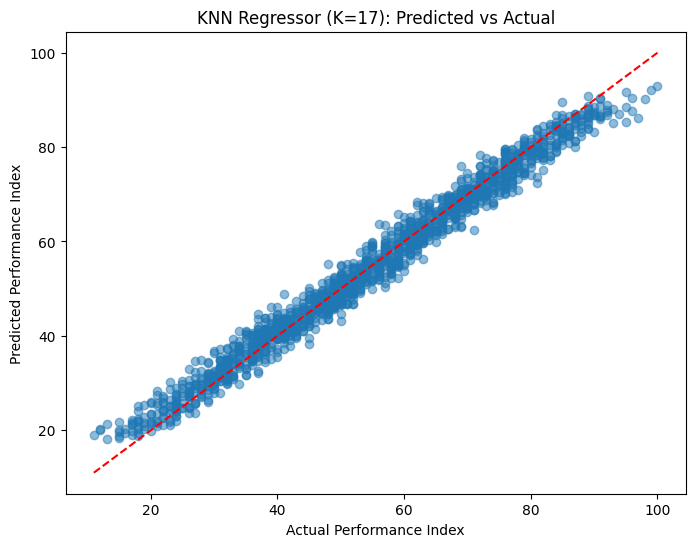

In [150]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, best_knn_val_pred, alpha=0.5)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    'r--'
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("KNN Regressor (K=17): Predicted vs Actual")

plt.show()

In [151]:
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "KNN (K=17)"],
    "MAE": [mae, best_knn_mae],
    "RMSE": [rmse, best_knn_rmse],
    "R2": [r2, best_knn_r2]
})

display(comparison_df)

,Model,MAE,RMSE,R2
0,Linear Regression,2.235332,2.829029,0.988941
1,KNN (K=17),2.245740,2.828252,0.977833


In [152]:
print("Linear Regression:")
print("MAE:", mean_absolute_error(y_val, y_val_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_val_pred)))
print("R2:", r2_score(y_val, y_val_pred))

print("\nKNN (K=17):")
print("MAE:", mean_absolute_error(y_val, best_knn_val_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, best_knn_val_pred)))
print("R2:", r2_score(y_val, best_knn_val_pred))

Linear Regression:
MAE: 1.5968564874126214
RMSE: 1.9976554953300847
R2: 0.9889412776643998

KNN (K=17):
MAE: 2.24574015966954
RMSE: 2.8282524114769063
R2: 0.9778333482966933


In [153]:
lr_mae_val = mean_absolute_error(y_val, y_pred= y_val_pred)
lr_rmse_val = np.sqrt(mean_squared_error(y_val, y_val_pred))
lr_r2_val = r2_score(y_val, y_val_pred)

knn_mae_val = mean_absolute_error(y_val, best_knn_val_pred)
knn_rmse_val = np.sqrt(mean_squared_error(y_val, best_knn_val_pred))
knn_r2_val = r2_score(y_val, best_knn_val_pred)

In [154]:
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "KNN (K=17)"],
    "MAE": [lr_mae_val, knn_mae_val],
    "RMSE": [lr_rmse_val, knn_rmse_val],
    "R2": [lr_r2_val, knn_r2_val]
})

display(comparison_df)

,Model,MAE,RMSE,R2
0,Linear Regression,1.596856,1.997655,0.988941
1,KNN (K=17),2.245740,2.828252,0.977833


In [155]:
lr_test_pred = lr_model.predict(X_test)

knn_test_pred = best_knn_model.predict(X_test)

In [156]:
lr_mae_test = mean_absolute_error(y_test, lr_test_pred)
lr_rmse_test = np.sqrt(mean_squared_error(y_test, lr_test_pred))
lr_r2_test = r2_score(y_test, lr_test_pred)

knn_mae_test = mean_absolute_error(y_test, knn_test_pred)
knn_rmse_test = np.sqrt(mean_squared_error(y_test, knn_test_pred))
knn_r2_test = r2_score(y_test, knn_test_pred)

In [157]:
test_comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "KNN (K=17)"],
    "MAE": [lr_mae_test, knn_mae_test],
    "RMSE": [lr_rmse_test, knn_rmse_test],
    "R2": [lr_r2_test, knn_r2_test]
})

display(test_comparison_df)

,Model,MAE,RMSE,R2
0,Linear Regression,1.695543,2.159105,0.987379
1,KNN (K=17),2.391905,3.029635,0.975151


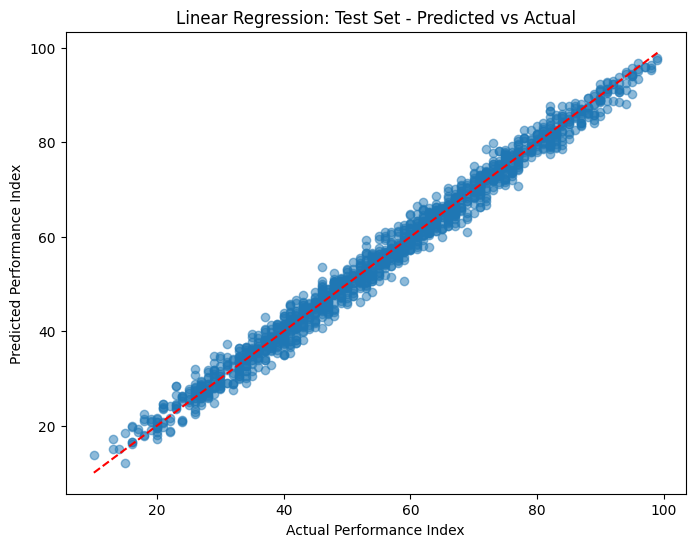

In [158]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Linear Regression: Test Set - Predicted vs Actual")

plt.show()

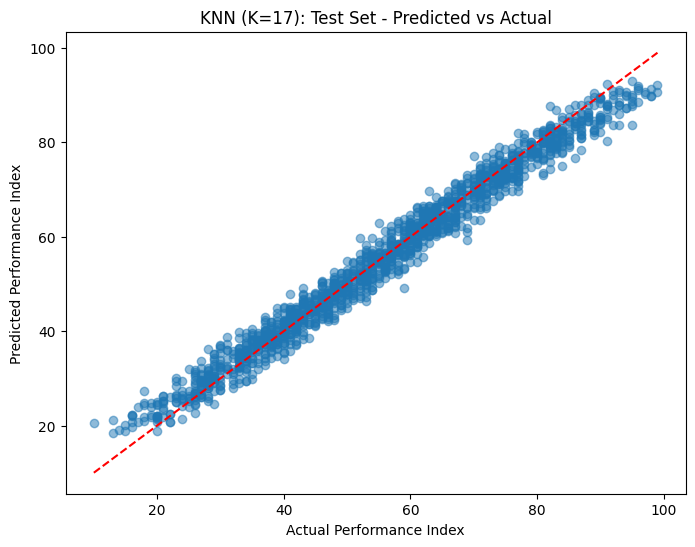

In [159]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, knn_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("KNN (K=17): Test Set - Predicted vs Actual")

plt.show()

In [160]:
weights = np.zeros(X_train.shape[1])

In [161]:
print(weights)

[0. 0. 0. 0. 0.]


In [162]:
bias = 0

In [163]:
y_pred_scratch = np.dot(X_train, weights) + bias

In [164]:
print(y_pred_scratch[:5])

[0. 0. 0. 0. 0.]


In [165]:
print("Predicted:", y_pred_scratch[:5])
print("Actual:", y_train.iloc[:5].values)

Predicted: [0. 0. 0. 0. 0.]
Actual: [75. 72. 81. 48. 76.]


In [166]:
mse = np.mean((y_train - y_pred_scratch) ** 2)

print("MSE:", mse)

MSE: 3404.479670091159


In [167]:
dw = (-2 / len(X_train)) * np.dot(X_train.T, (y_train - y_pred_scratch))

In [168]:
print(dw)

[-14.60956254 -35.2550621   -0.83454071  -1.70624072  -1.4123643 ]


In [169]:
db = (-2 / len(X_train)) * np.sum(y_train - y_pred_scratch)

print(db)

-110.16495442048907


In [170]:
learning_rate = 0.01

weights = weights - learning_rate * dw
bias = bias - learning_rate * db

print("Updated Weights:", weights)
print("Updated Bias:", bias)

Updated Weights: [0.14609563 0.35255062 0.00834541 0.01706241 0.01412364]
Updated Bias: 1.1016495442048908


In [171]:
y_pred_scratch = np.dot(X_train, weights) + bias

print("Predicted:", y_pred_scratch[:5])
print("Actual:", y_train[:5].values)

Predicted: [1.47186118 1.37997926 1.58948088 0.96223079 1.48128706]
Actual: [75. 72. 81. 48. 76.]


In [172]:
mse = np.mean((y_train - y_pred_scratch) ** 2)

print("New MSE:", mse)

New MSE: 3269.85641550615


In [173]:
learning_rate = 0.01
epochs = 1000

for i in range(epochs):

    y_pred_scratch = np.dot(X_train, weights) + bias

    dw = (-2 / len(X_train)) * np.dot(X_train.T, (y_train - y_pred_scratch))

    db = (-2 / len(X_train)) * np.sum(y_train - y_pred_scratch)

    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

In [174]:
y_pred_scratch = np.dot(X_train, weights) + bias

final_mse = np.mean((y_train - y_pred_scratch) ** 2)

print("Final MSE:", final_mse)

Final MSE: 4.113767834217854


In [175]:
print("Predicted:", y_pred_scratch[:5])
print("Actual:", y_train[:5].values)

Predicted: [73.96974804 69.44385917 79.28778182 48.20300284 74.14182377]
Actual: [75. 72. 81. 48. 76.]


In [176]:
scratch_mae = mean_absolute_error(y_train, y_pred_scratch)

scratch_rmse = np.sqrt(mean_squared_error(y_train, y_pred_scratch))

scratch_r2 = r2_score(y_train, y_pred_scratch)

print("Scratch MAE:", scratch_mae)
print("Scratch RMSE:", scratch_rmse)
print("Scratch R2:", scratch_r2)

Scratch MAE: 1.6134609674864333
Scratch RMSE: 2.0282425481726425
Scratch R2: 0.9888937265788157


In [177]:
scratch_val_pred = np.dot(X_val, weights) + bias

print("Predicted:", scratch_val_pred[:5])
print("Actual:", y_val[:5].values)

Predicted: [62.59416335 71.99797955 79.69093237 47.58032416 58.50963775]
Actual: [62. 71. 80. 48. 60.]


In [178]:
scratch_val_mae = mean_absolute_error(y_val, scratch_val_pred)

scratch_val_rmse = np.sqrt(mean_squared_error(y_val, scratch_val_pred))

scratch_val_r2 = r2_score(y_val, scratch_val_pred)

print("Validation MAE:", scratch_val_mae)
print("Validation RMSE:", scratch_val_rmse)
print("Validation R2:", scratch_val_r2)

Validation MAE: 1.5968564884955159
Validation RMSE: 1.9976554980259678
Validation R2: 0.9889412776345518


In [179]:
scratch_test_pred = np.dot(X_test, weights) + bias

print("Predicted:", scratch_test_pred[:5])
print("Actual:", y_test[:5].values)

Predicted: [27.19556002 38.52485202 56.60564199 65.91568063 38.18772759]
Actual: [27. 36. 54. 65. 42.]


In [180]:
scratch_test_mae = mean_absolute_error(y_test, scratch_test_pred)

scratch_test_rmse = np.sqrt(mean_squared_error(y_test, scratch_test_pred))

scratch_test_r2 = r2_score(y_test, scratch_test_pred)

print("Test MAE:", scratch_test_mae)
print("Test RMSE:", scratch_test_rmse)
print("Test R2:", scratch_test_r2)

Test MAE: 1.6955430046945503
Test RMSE: 2.1591046757786647
Test R2: 0.9873794130536484


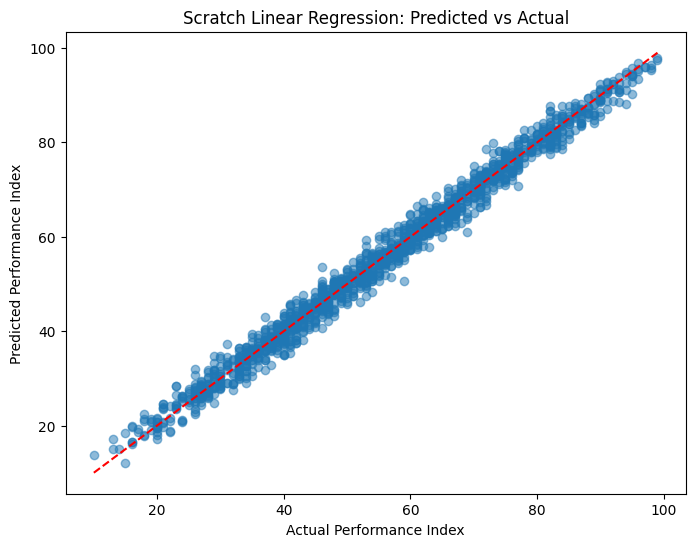

In [181]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, scratch_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Scratch Linear Regression: Predicted vs Actual")

plt.show()